In [1]:
!pip install --upgrade binance-historical-data plotly -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 56.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 21.1 MB/s eta 0:00:00


In [2]:
import os
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime, timedelta, date, time
from binance_historical_data import BinanceDataDumper
warnings.filterwarnings('ignore')

def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",  # spot, um, cm
        data_type="klines",  # aggTrades, klines, trades
        data_frequency="5m",
    )
    return data_dumper.get_list_all_trading_pairs()

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data



In [ ]:
ticker = 'BTCUSDT'
data_frequency = '15m'
download_ticker(ticker, "2022-01-01", "2024-07-25", data_frequency)
df = process_csv_files(ticker, data_frequency)
df = df.drop(columns=['close_time',	'quote_asset_volume',	'number_of_trades',	'taker_buy_base_asset_volume',	'taker_buy_quote_asset_volume',	'ignore'])
df.set_index('open_time', inplace=True)
df

---> Found overall tickers: 601
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 15m
---> Start Date: 20220101
---> End Date: 20240725


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download:   0%|          | 0/30 [00:00<?, ?files/s]

daily files to download:   0%|          | 0/25 [00:00<?, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For BTCUSDT new data saved for: 30 months 25 days
---> For BTCUSD new data saved for: 0 months 0 days


,Open,High,Low,Close,volume
open_time,,,,,
2022-01-01 00:15:00,46332.52,46421.27,46236.27,46375.42,319.99973
2022-01-01 00:30:00,46375.42,46689.42,46360.19,46610.81,386.08077
2022-01-01 00:45:00,46610.81,46731.39,46575.76,46656.13,410.59336
2022-01-01 01:00:00,46656.14,46767.24,46574.06,46766.99,330.08774
2022-01-01 01:15:00,46766.99,46949.99,46752.17,46815.33,259.42027
...,...,...,...,...,...
2024-07-25 22:45:00,65726.00,65766.00,65639.89,65644.00,87.50593
2024-07-25 23:00:00,65644.01,65768.05,65630.00,65752.77,179.35508
2024-07-25 23:15:00,65752.78,65825.36,65686.18,65716.39,74.32388


In [ ]:
# Calculate moving average for prices
short_window = 7    #Adjust params here
long_window = 28
df['MA_long'] = df['Close'].rolling(window=long_window).mean()
df['MA_short'] = df['Close'].rolling(window=short_window).mean()

# Position
df['Position'] = np.select((
    (df['MA_short'] > df['MA_long']) & (df['MA_short'].shift(1) < df['MA_long'].shift(1)),
    (df['MA_short'] < df['MA_long']) & (df['MA_short'].shift(1) > df['MA_long'].shift(1))),
                           (1, -1),
                           default=0)
df['Position'] = df['Position'].replace(0, method='ffill')

df.head(100)

,Open,High,Low,Close,volume,MA_long,MA_short,Position
open_time,,,,,,,,
2022-01-01 00:15:00,46332.52,46421.27,46236.27,46375.42,319.99973,NaN,NaN,0
2022-01-01 00:30:00,46375.42,46689.42,46360.19,46610.81,386.08077,NaN,NaN,0
2022-01-01 00:45:00,46610.81,46731.39,46575.76,46656.13,410.59336,NaN,NaN,0
2022-01-01 01:00:00,46656.14,46767.24,46574.06,46766.99,330.08774,NaN,NaN,0
2022-01-01 01:15:00,46766.99,46949.99,46752.17,46815.33,259.42027,NaN,NaN,0
...,...,...,...,...,...,...,...,...
2022-01-02 00:00:00,47722.66,47750.00,47463.63,47517.62,294.05935,47467.547857,47484.377143,1
2022-01-02 00:15:00,47517.63,47578.79,47381.12,47544.70,324.85868,47475.199643,47498.150000,1
2022-01-02 00:30:00,47544.70,47699.39,47491.43,47638.95,266.91970,47467.803571,47526.465714,1


In [ ]:
def calculate_returns(pos,close):
  entry = [0] * len(pos)
  pnls = [0] * len(pos)
  fee = 0.05/100
  for i in range (1,len(pos)):
    if pos[i] == pos[i-1]:
      entry[i] = entry[i-1]
    elif pos[i] != pos[i-1]:
      entry[i] = close[i]

  for i in range (1,len(pos)):
    if entry[i] != entry[i-1]:
      pnls[i] = (entry[i] - entry[i-1])*pos[i-1]*(1-fee)

  return entry, pnls

df['Price'], df['Pnls'] = calculate_returns(df['Position'], df['Close'])


df.head (500) # Display the DataFrame

,Open,High,Low,Close,volume,MA_long,MA_short,Position,Price,Pnls
open_time,,,,,,,,,,
2022-01-01 00:15:00,46332.52,46421.27,46236.27,46375.42,319.99973,NaN,NaN,0,0.00,0.0
2022-01-01 00:30:00,46375.42,46689.42,46360.19,46610.81,386.08077,NaN,NaN,0,0.00,0.0
2022-01-01 00:45:00,46610.81,46731.39,46575.76,46656.13,410.59336,NaN,NaN,0,0.00,0.0
2022-01-01 01:00:00,46656.14,46767.24,46574.06,46766.99,330.08774,NaN,NaN,0,0.00,0.0
2022-01-01 01:15:00,46766.99,46949.99,46752.17,46815.33,259.42027,NaN,NaN,0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...
2022-01-06 04:00:00,42835.00,43063.55,42762.34,43026.14,962.77098,43432.932857,43134.871429,-1,46157.99,0.0
2022-01-06 04:15:00,43026.13,43159.17,42821.22,42821.23,585.60939,43391.972143,43052.191429,-1,46157.99,0.0
2022-01-06 04:30:00,42821.22,42995.26,42600.05,42772.18,929.68917,43359.803214,42982.568571,-1,46157.99,0.0


In [ ]:
count_positive = (df['Pnls'] > 0).sum()
sum_positive = df[df['Pnls'] > 0]['Pnls'].sum()

count_negative = (df['Pnls'] < 0).sum()
sum_negative = df[df['Pnls'] < 0]['Pnls'].sum()

print(f'Số lệnh lãi: {count_positive}')
print(f'Số lệnh lỗ: {count_negative}')
print(f'Tổng lãi: {sum_positive}')
print(f'Lãi trung bình: {sum_positive/count_positive}')
print(f'Tổng lỗ: {sum_negative}')
print(f'Lỗ trung bình: {sum_negative/count_negative}')

Số lệnh lãi: 1372
Số lệnh lỗ: 3103
Tổng lãi: 561989.894485
Lãi trung bình: 409.61362571793006
Tổng lỗ: -558947.076655
Lỗ trung bình: -180.1311880937802


In [ ]:
def longest_negative_streak(data):
    arr = np.array(data)

    # Mask for negatives
    neg_mask = arr < 0

    # Split into groups where non-negatives break the streak
    streaks = np.split(arr[neg_mask], np.where(~neg_mask)[0])

    # Filter out empty arrays
    streaks = [s for s in streaks if len(s) > 0]

    if not streaks:
        return 0, 0, []

    # Longest streak (by length)
    longest = max(streaks, key=len)
    longest_count = len(longest)

    # Streak with the highest sum (least negative)
    highest_sum_streak = max(streaks, key=np.sum)
    highest_sum = highest_sum_streak.sum()

    return longest_count, highest_sum, longest.tolist()


data = [-3,0,2,3,4,-5,-6,-2,8,4,3,0,0,4,-2,-8,0,-3,-6,-7]
longest_negative_streak(data)






(4, np.int64(-2), [-2, -8, -3, -6])

In [ ]:
def longest_negative_streak(data):
    current = []
    count_list = []
    total_list = []
    # average = []      # Dùng numpy để tính cái này sau
    total = 0
    count = 0
    longest_count = 0
    highest_sum = 0

    for num in data:
        if num < 0:
            current.append(num)
        else:
          if current != []:
            count = len(current)
            total = sum(current)
            count_list.append(count)
            total_list.append(total)
            if abs(total) > abs(highest_sum):
              highest_sum = total
            if count > longest_count:
              longest_count = count
              longest = current

            current = []
            count = 0
            total = 0

    return count, highest_sum


pnls = df['Pnls'].tolist()
pnls_no_0 = [x for x in pnls if x != 0]
print("Longest negative streak:", longest_negative_streak(pnls_no_0))
print("Longest negative streak:", longest_negative_streak(pnls_no_0))


Longest negative streak: (0, -7519.19852)
Longest negative streak: (0, -7519.19852)


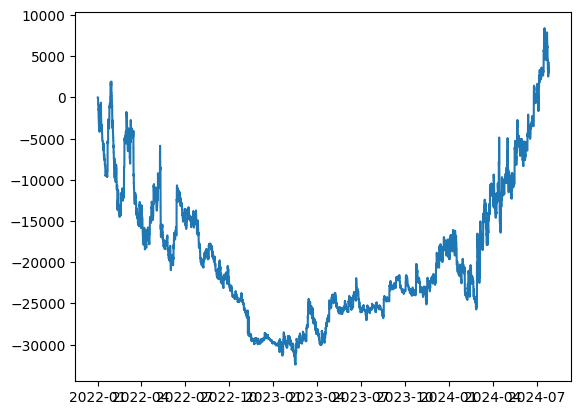

In [ ]:
dates = df.index.tolist()

# Plot profit
# plt.plot(unrealised_dates, np.cumprod(1+np.array(unrealised))-1)
# plt.plot(dates, np.cumprod(1+np.array(pnls))-1)
#plt.plot(dates,np.cumprod(1+np.array(pnls))-1)
# plt.plot(unrlzd_dates,np.cumprod(1+np.array(unrlzd)))
plt.plot(dates, np.cumsum(pnls))
#plt.plot(unrlzd_dates, np.cumsum(unrlzd))